# 01 - EDA: Bank Account Fraud (BAF) dataset

In this notebook I explore the BAF dataset before building any model.

Questions I want to answer:
1. How big is the data, and what are the columns?
2. What share of the rows is fraud? Is the data imbalanced?
3. Are there missing values, and how are they encoded?
4. Which columns behave differently for fraud vs. non-fraud?
5. How does fraud change over time (`month`)? This decides my train/test split.
6. Are there columns with no useful information (a single value)?

I only use `Base.csv` here. I keep the `Variant` files for fairness experiments later.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Project root = the folder that contains pyproject.toml
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "raw" / "fraud_baf" / "Base.csv"
FIG_DIR = ROOT / "reports" / "figures" / "fraud"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 1. Load and inspect the data

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")
df.head()

Rows: 1,000,000   Columns: 32
Memory: 276 MB


,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,13096.035018,7850.955007,6742.080561,5,5,CB,163,1,BC,0,1,9,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,9223.283431,5745.251481,5941.664859,3,18,CA,154,1,BC,1,1,2,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,4471.472149,5471.988958,5992.555113,15,11,CA,89,1,BC,0,1,30,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,14431.993621,6755.344479,5970.336831,11,13,CA,90,1,BC,0,1,1,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,7601.511579,5124.046930,5940.734212,1,6,CA,91,0,BC,1,1,26,0,200.0,0,INTERNET,3.743048,other,0,1,0,0


In [3]:
df.dtypes.value_counts()

int64      18
float64     9
str         5
Name: count, dtype: int64

In [4]:
# Categorical (text) columns and their values
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
for c in cat_cols:
    print(f"{c:18s} {df[c].nunique()} values: {sorted(df[c].unique())}")

payment_type       5 values: ['AA', 'AB', 'AC', 'AD', 'AE']
employment_status  7 values: ['CA', 'CB', 'CC', 'CD', 'CE', 'CF', 'CG']
housing_status     7 values: ['BA', 'BB', 'BC', 'BD', 'BE', 'BF', 'BG']
source             2 values: ['INTERNET', 'TELEAPP']


device_os          5 values: ['linux', 'macintosh', 'other', 'windows', 'x11']


## 2. Target distribution

`fraud_bool = 1` means the bank account application was fraudulent.

In [5]:
counts = df["fraud_bool"].value_counts()
rate = df["fraud_bool"].mean()
print(counts)
print(f"\nFraud rate: {rate:.2%}  ->  about 1 fraud in every {1 / rate:.0f} applications")

fraud_bool
0    988971
1     11029
Name: count, dtype: int64

Fraud rate: 1.10%  ->  about 1 fraud in every 91 applications


The data is highly imbalanced. A model that always predicts "not fraud" would reach about 99% accuracy
and still catch no fraud, so accuracy is not a useful metric here. I will evaluate with **PR-AUC** and
**recall at a fixed false-positive rate** (the BAF paper uses recall at 5% FPR).

## 3. Missing values

The CSV has no empty cells, but according to the dataset documentation, missing values are encoded as
negative numbers in these columns: `prev_address_months_count`, `current_address_months_count`,
`bank_months_count`, `session_length_in_minutes`, `device_distinct_emails_8w` and `intended_balcon_amount`.

In [6]:
print("Empty cells (NaN) in the whole table:", int(df.isna().sum().sum()))

missing_cols = [
    "prev_address_months_count", "current_address_months_count", "bank_months_count",
    "session_length_in_minutes", "device_distinct_emails_8w", "intended_balcon_amount",
]
rows = []
for c in missing_cols:
    is_missing = df[c] < 0
    rows.append({
        "column": c,
        "missing_%": round(100 * is_missing.mean(), 2),
        "fraud_rate_when_missing_%": round(100 * df.loc[is_missing, "fraud_bool"].mean(), 2),
        "fraud_rate_when_present_%": round(100 * df.loc[~is_missing, "fraud_bool"].mean(), 2),
    })
missing_table = pd.DataFrame(rows).sort_values("missing_%", ascending=False)
missing_table

Empty cells (NaN) in the whole table: 0


,column,missing_%,fraud_rate_when_missing_%,fraud_rate_when_present_%
5,intended_balcon_amount,74.25,1.31,0.50
0,prev_address_months_count,71.29,1.42,0.31
2,bank_months_count,25.36,1.63,0.92
1,current_address_months_count,0.43,0.33,1.11
3,session_length_in_minutes,0.20,0.89,1.10
4,device_distinct_emails_8w,0.04,1.11,1.10


When the fraud rate differs between "missing" and "present", missingness itself carries signal.
For these columns I will add indicator features (e.g. `bank_months_count_missing`) instead of only imputing the value.

## 4. Constant columns

In [7]:
nunique = df.nunique().sort_values()
nunique.head(8)

device_fraud_count    1
fraud_bool            2
keep_alive_session    2
foreign_request       2
phone_home_valid      2
has_other_cards       2
email_is_free         2
source                2
dtype: int64

## 5. Fraud over time (`month`)

In [8]:
by_month = df.groupby("month")["fraud_bool"].agg(rows="size", frauds="sum", fraud_rate="mean")
by_month["fraud_rate_%"] = (100 * by_month.pop("fraud_rate")).round(2)
by_month

,rows,frauds,fraud_rate_%
month,,,
0,132440,1500,1.13
1,127620,1198,0.94
2,136979,1198,0.87
3,150936,1392,0.92
4,127691,1452,1.14
5,119323,1411,1.18
6,108168,1450,1.34
7,96843,1428,1.47


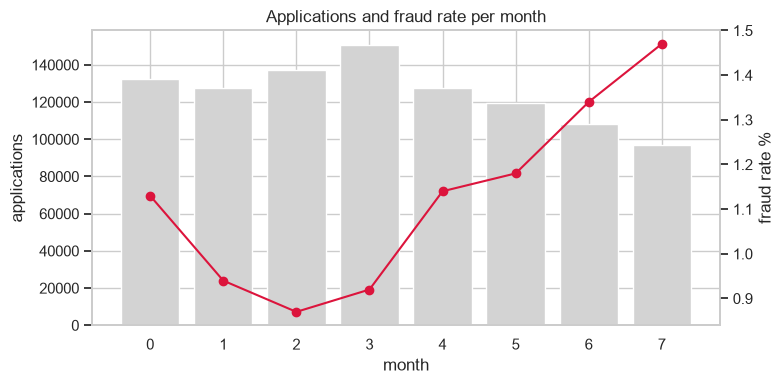

In [9]:
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(by_month.index, by_month["rows"], color="lightgray", label="applications")
ax1.set_xlabel("month")
ax1.set_ylabel("applications")
ax2 = ax1.twinx()
ax2.plot(by_month.index, by_month["fraud_rate_%"], color="crimson", marker="o", label="fraud rate %")
ax2.set_ylabel("fraud rate %")
ax2.grid(False)
ax1.set_title("Applications and fraud rate per month")
fig.tight_layout()
fig.savefig(FIG_DIR / "fraud_by_month.png", dpi=120)
plt.show()

In production, a model is trained on past data and scores future applications. A random split would leak
future information into training, so I will use a **time-based split**: train on months 0-5, test on months 6-7
(same as the BAF paper).

## 6. Fraud rate per category

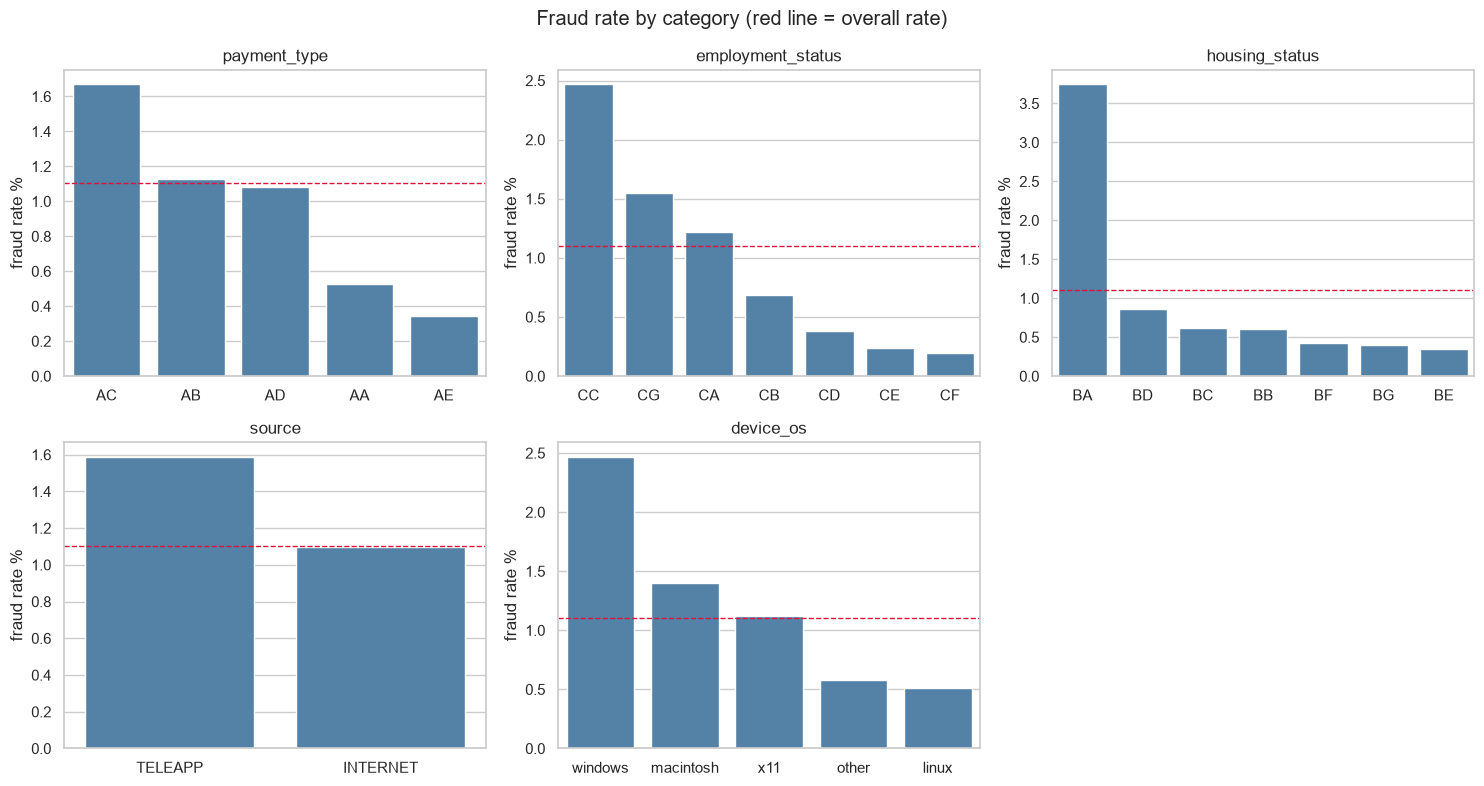

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, cat_cols):
    rate_by_cat = df.groupby(c)["fraud_bool"].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate_by_cat.index, y=rate_by_cat.values, ax=ax, color="steelblue")
    ax.axhline(100 * rate, color="crimson", linestyle="--", linewidth=1)  # overall fraud rate
    ax.set_title(c)
    ax.set_ylabel("fraud rate %")
    ax.set_xlabel("")
for ax in axes.flat[len(cat_cols):]:
    ax.remove()
fig.suptitle("Fraud rate by category (red line = overall rate)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fraud_rate_by_category.png", dpi=120)
plt.show()

## 7. Numeric columns: fraud vs. non-fraud

For each numeric column I compare the median for fraud and non-fraud, and its correlation with the target.
Correlation only captures linear relationships, so this is a first signal, not a final ranking.

In [11]:
# Skip the target, the time column and constant columns (correlation is undefined for them)
num_cols = [c for c in df.select_dtypes("number").columns
            if c not in ("fraud_bool", "month") and df[c].nunique() > 1]
compare = df.groupby("fraud_bool")[num_cols].median().T
compare.columns = ["median_not_fraud", "median_fraud"]
compare["corr_with_fraud"] = df[num_cols].corrwith(df["fraud_bool"]).round(3)
compare.sort_values("corr_with_fraud", key=abs, ascending=False)

,median_not_fraud,median_fraud,corr_with_fraud
credit_risk_score,122.000000,178.000000,0.071
proposed_credit_limit,200.000000,500.000000,0.069
customer_age,30.000000,40.000000,0.063
keep_alive_session,1.000000,0.000000,-0.050
income,0.600000,0.800000,0.045
date_of_birth_distinct_emails_4w,9.000000,7.000000,-0.043
name_email_similarity,0.493571,0.292420,-0.037
device_distinct_emails_8w,1.000000,1.000000,0.036
phone_home_valid,0.000000,0.000000,-0.035
has_other_cards,0.000000,0.000000,-0.035


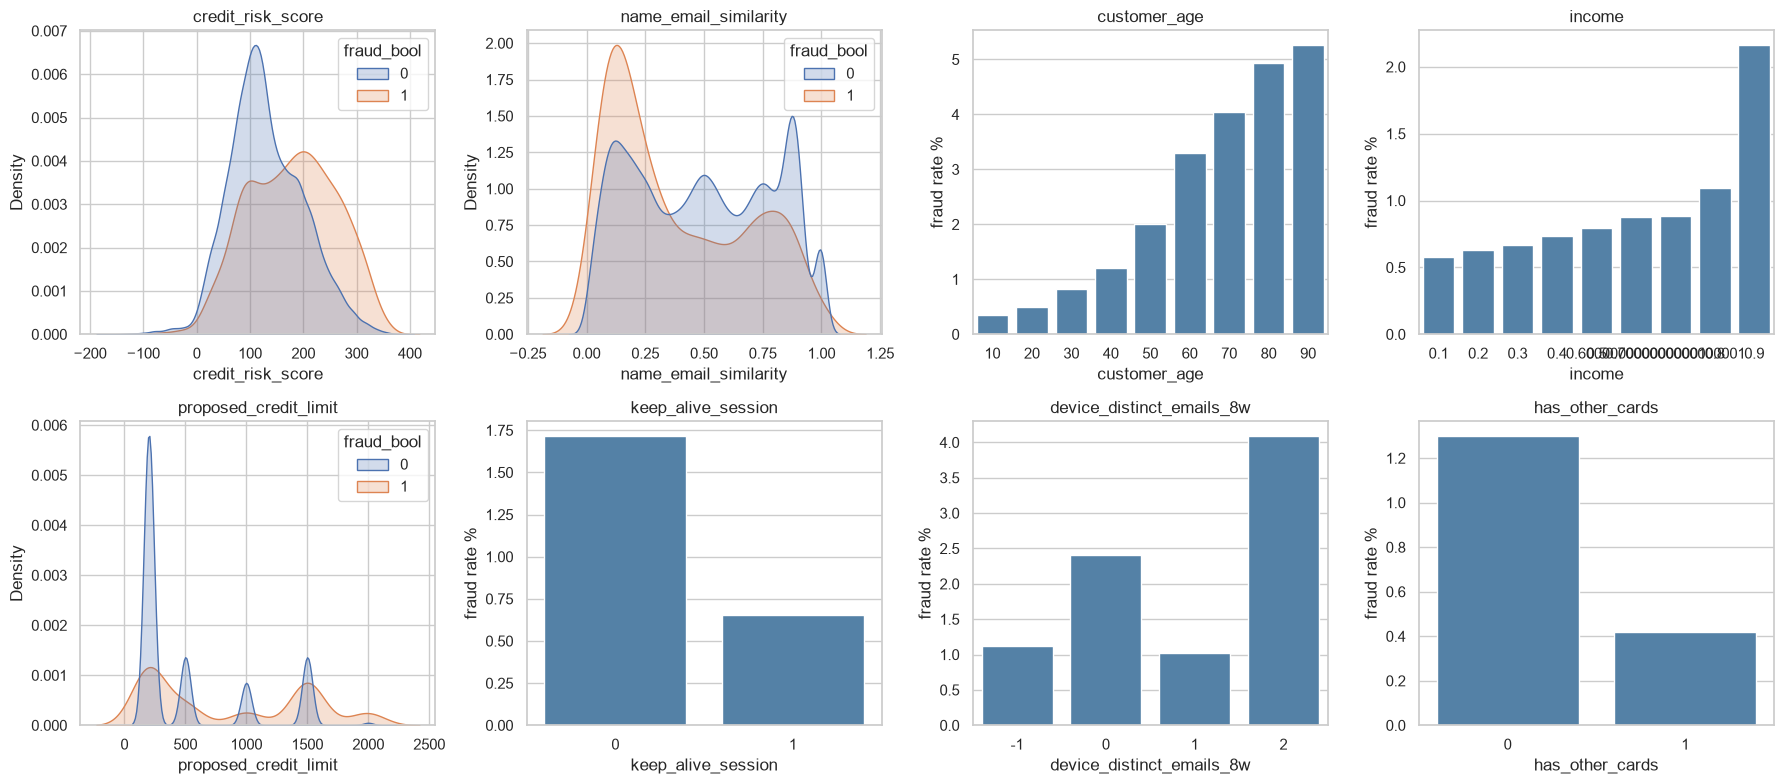

In [12]:
top = ["credit_risk_score", "name_email_similarity", "customer_age", "income",
       "proposed_credit_limit", "keep_alive_session", "device_distinct_emails_8w", "has_other_cards"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.flat, top):
    if df[c].nunique() <= 10:
        # Few distinct values: fraud rate per value
        r = df.groupby(c)["fraud_bool"].mean().mul(100)
        sns.barplot(x=r.index, y=r.values, ax=ax, color="steelblue")
        ax.set_ylabel("fraud rate %")
    else:
        # Many distinct values: compare the distributions
        sns.kdeplot(data=df.sample(200_000, random_state=0), x=c, hue="fraud_bool",
                    common_norm=False, fill=True, ax=ax)
    ax.set_title(c)
fig.tight_layout()
fig.savefig(FIG_DIR / "numeric_fraud_vs_not.png", dpi=120)
plt.show()

## 8. Fraud rate by age group

In [13]:
age = df.groupby("customer_age")["fraud_bool"].agg(rows="size", fraud_rate="mean")
age["fraud_rate_%"] = (100 * age.pop("fraud_rate")).round(2)
age

,rows,fraud_rate_%
customer_age,,
10,20987,0.35
20,245855,0.49
30,311433,0.83
40,238712,1.20
50,140353,2.00
60,34770,3.30
70,6517,4.04
80,1297,4.93
90,76,5.26


`customer_age` is a protected attribute. Besides predictive performance, I need to check that the model does not
treat age groups unfairly, e.g. by comparing false-positive rates for applicants under and over 50 with `fairlearn`.

## 9. Summary and next steps

| # | Finding | Decision |
|---|---|---|
| 1 | 1,000,000 rows, 32 columns, ~276 MB in memory. 5 categorical columns, the rest numeric. | Store the data as **Parquet** (smaller, faster, keeps column types). |
| 2 | Only **1.10%** of applications are fraud (11,029 rows). | Evaluate with **PR-AUC** and **recall at 5% FPR**, not accuracy. Try class weights. |
| 3 | No NaNs, but missing values are encoded as **negative numbers**: `intended_balcon_amount` (74%), `prev_address_months_count` (71%), `bank_months_count` (25%). | Add **missing-indicator** features; the fraud rate differs between missing and present. |
| 4 | `device_fraud_count` is **constant** (always 0). | **Drop** it. |
| 5 | The fraud rate **rises in the last months** (~0.9% in months 1-3, 1.47% in month 7) while volume drops. | **Time-based split** (train months 0-5, test 6-7) and **drift monitoring** in production. |
| 6 | Some categories are much riskier: `housing_status = BA` (3.7%), `employment_status = CC` (2.5%), `device_os = windows` (2.5%), `payment_type = AC` (1.7%). | Keep and encode these columns (one-hot, or native categorical support in LightGBM). |
| 7 | Fraud applications have a higher `credit_risk_score` and `proposed_credit_limit`, lower `name_email_similarity`, are older, and more often have `keep_alive_session = 0`. | Likely strong features; confirm with SHAP after training. |
| 8 | The fraud rate grows strongly with **age** (0.5% at 20, 3.3% at 60, ~5% at 80+). | Treat `customer_age` as a protected attribute and run a **fairness** check with `fairlearn`. |

All single-feature correlations with the target are weak (below 0.08). No single column separates fraud on its own,
which supports using a model that combines many features, such as gradient boosting.